In [2]:
!pip install -q datasets transformers accelerate evaluate scikit-learn gradio


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("Mouwiya/cfpb-consumer-complaints", split="train", streaming=True)
muestra = list(ds.take(2000))
df = pd.DataFrame(muestra)

print(df.columns.tolist())
print(df.shape)
print(df.isna().mean().round(2))
print(df.head(3).to_string())

README.md:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

c:\Users\Julian\miniconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Julian\.cache\huggingface\hub\datasets--Mouwiya--cfpb-consumer-complaints. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Resolving data files:   0%|          | 0/68 [00:00<?, ?it/s]

['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'complaint_id']
(2000, 16)
date_received                   0.00
product                         0.00
sub_product                     0.00
issue                           0.00
sub_issue                       0.01
consumer_complaint_narrative    0.94
company_public_response         0.54
company                         0.00
state                           0.00
zip_code                        0.00
tags                            0.98
submitted_via                   0.00
date_sent_to_company            0.01
company_response_to_consumer    0.22
timely_response                 0.00
complaint_id                    0.00
dtype: float64
              date_received       product                     sub_product                                 iss

In [4]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU")

False sin GPU


In [5]:
import os, random
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import list_repo_files, hf_hub_download
from google.colab import drive

drive.mount('/content/drive')

repo = "Mouwiya/cfpb-consumer-complaints"
archivos = [f for f in list_repo_files(repo, repo_type="dataset") if f.endswith(".parquet")]
print("Archivos parquet:", len(archivos))

random.Random(42).shuffle(archivos)
cols = ["complaint_id", "date_received", "product", "issue", "consumer_complaint_narrative"]

partes, total = [], 0
for i, f in enumerate(archivos):
    ruta = hf_hub_download(repo, f, repo_type="dataset")
    t = pq.read_table(ruta, columns=cols).to_pandas()
    t = t[t["consumer_complaint_narrative"].notna()]
    if len(t) > 1500:
        t = t.sample(1500, random_state=42)
    partes.append(t)
    total += len(t)
    print(f"{i+1}/{len(archivos)} | acumulado: {total}")
    if total >= 60000:
        break

df = pd.concat(partes, ignore_index=True)
df.to_parquet("/content/drive/MyDrive/muestra_cfpb.parquet")
print("Guardado en Drive. Filas:", len(df))

ModuleNotFoundError: No module named 'google.colab'

In [ ]:
import pandas as pd

df = pd.read_parquet("/content/drive/MyDrive/muestra_cfpb.parquet")
df["date_received"] = pd.to_datetime(df["date_received"], utc=True, errors="coerce")

print(df.shape)
print(df["date_received"].min(), df["date_received"].max())
print("\nProductos:")
print(df["product"].value_counts())
print("\nTop 15 issues:")
print(df["issue"].value_counts().head(15))
df["n_palabras"] = df["consumer_complaint_narrative"].str.split().str.len()
print("\nLongitud en palabras:")
print(df["n_palabras"].describe())
print("\nDuplicados exactos:", df["consumer_complaint_narrative"].duplicated().sum())

(61482, 5)
2015-03-19 00:00:00+00:00 2026-06-17 11:11:22+00:00

Productos:
product
Credit reporting or other personal consumer reports                             26290
Debt collection                                                                  9396
Credit reporting, credit repair services, or other personal consumer reports     7071
Checking or savings account                                                      4414
Credit card                                                                      3655
Mortgage                                                                         2486
Money transfer, virtual currency, or money service                               2479
Student loan                                                                     1243
Vehicle loan or lease                                                            1206
Credit card or prepaid card                                                      1094
Payday loan, title loan, personal loan, or advance loan  

In [ ]:
import re, os
import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split

drive.mount('/content/drive')
df = pd.read_parquet("/content/drive/MyDrive/muestra_cfpb.parquet")

# 1) Tema = agrupación de productos
MAPA_TEMA = {
    "Credit reporting or other personal consumer reports": "Reportes de crédito",
    "Credit reporting, credit repair services, or other personal consumer reports": "Reportes de crédito",
    "Credit reporting": "Reportes de crédito",
    "Debt collection": "Cobro de deudas",
    "Debt or credit management": "Cobro de deudas",
    "Checking or savings account": "Cuentas bancarias",
    "Bank account or service": "Cuentas bancarias",
    "Credit card": "Tarjetas",
    "Credit card or prepaid card": "Tarjetas",
    "Prepaid card": "Tarjetas",
    "Mortgage": "Hipotecas",
    "Student loan": "Préstamos",
    "Vehicle loan or lease": "Préstamos",
    "Payday loan, title loan, personal loan, or advance loan": "Préstamos",
    "Payday loan, title loan, or personal loan": "Préstamos",
    "Consumer Loan": "Préstamos",
    "Payday loan": "Préstamos",
    "Money transfer, virtual currency, or money service": "Transferencias de dinero",
    "Money transfers": "Transferencias de dinero",
    "Virtual currency": "Transferencias de dinero",
}
df["tema"] = df["product"].map(MAPA_TEMA)
df = df[df["tema"].notna()].copy()

# 2) Limpieza de texto
def limpiar(t):
    t = re.sub(r"\S+@\S+", " ", t)                                   # correos
    t = re.sub(r"\b\+?\d[\d\-\s().]{7,}\d\b", " ", t)                # teléfonos
    t = re.sub(r"\{\$[\d.,]+\}", " monto ", t)                        # montos {$25.00}
    t = re.sub(r"(?<![A-Za-z])(?:X{2,}[/\-]?)+(?![A-Za-z])", " ", t) # XXXX, XX/XX/XXXX
    return re.sub(r"\s+", " ", t).strip()

df["texto"] = df["consumer_complaint_narrative"].apply(limpiar)
df["n_palabras"] = df["texto"].str.split().str.len()
df = df[df["n_palabras"] >= 10]

# 3) Deduplicar ANTES de dividir (ignora mayúsculas)
antes = len(df)
df["clave"] = df["texto"].str.lower()
df = df.drop_duplicates(subset="clave").drop(columns="clave")
print(f"Filas antes de deduplicar: {antes} | después: {len(df)}")

# 4) Split estratificado 70/15/15
cols = ["complaint_id", "date_received", "product", "issue", "tema", "texto"]
df = df[cols].reset_index(drop=True)
train, temp = train_test_split(df, test_size=0.30, stratify=df["tema"], random_state=42)
valid, test = train_test_split(temp, test_size=0.50, stratify=temp["tema"], random_state=42)

os.makedirs("/content/drive/MyDrive/splits", exist_ok=True)
for nombre, parte in [("train", train), ("valid", valid), ("test", test)]:
    parte.to_parquet(f"/content/drive/MyDrive/splits/{nombre}.parquet")

print("\nTamaños:", len(train), len(valid), len(test))
print("\nDistribución de temas (train):")
print(train["tema"].value_counts())
print("\nEjemplo de texto limpio:\n", train["texto"].iloc[0][:400])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Filas antes de deduplicar: 61018 | después: 48823

Tamaños: 34176 7323 7324

Distribución de temas (train):
tema
Reportes de crédito         16190
Cobro de deudas              5714
Tarjetas                     3448
Cuentas bancarias            3160
Préstamos                    2379
Hipotecas                    1739
Transferencias de dinero     1546
Name: count, dtype: int64

Ejemplo de texto limpio:
 I am filling this formal complaint to address discrepancies found in my credit report and to request a fair and accurate resolution. I respectfully urge the credit bureaus to verify and correct my personal identifying information, including my full legal name, current address, date of birth, and the last digits of my Social Security number. Any information that is inaccurate, outdated, or unverifi


Entrenado en 75 s
                          precision    recall  f1-score   support

         Cobro de deudas      0.766     0.795     0.780      1225
       Cuentas bancarias      0.772     0.805     0.788       677
               Hipotecas      0.837     0.922     0.878       373
               Préstamos      0.660     0.824     0.733       510
     Reportes de crédito      0.937     0.851     0.892      3469
                Tarjetas      0.713     0.789     0.749       739
Transferencias de dinero      0.755     0.755     0.755       331

                accuracy                          0.828      7324
               macro avg      0.777     0.820     0.796      7324
            weighted avg      0.838     0.828     0.831      7324

Macro-F1: 0.7964 | Accuracy: 0.8284


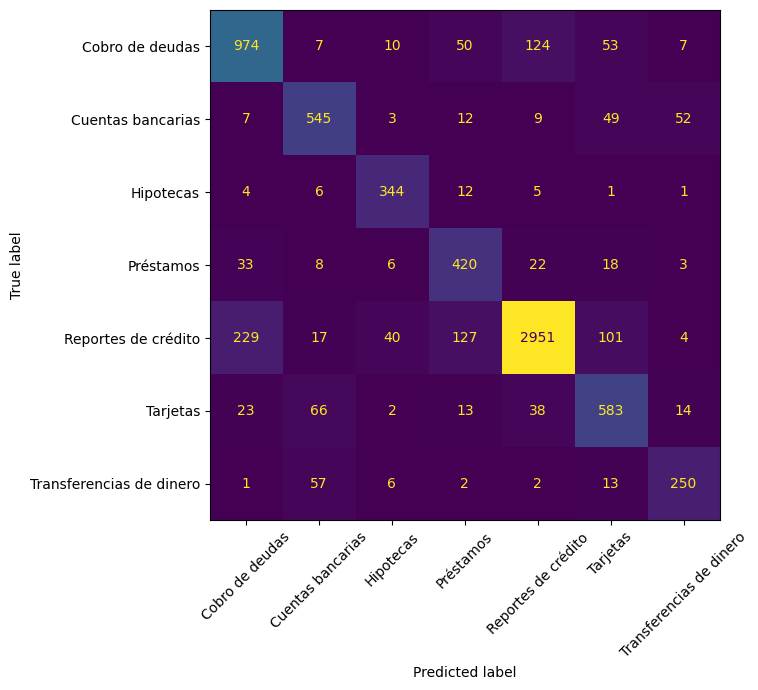

In [ ]:
import time, json, joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200000, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=300, class_weight="balanced")),
])

t0 = time.time()
baseline.fit(train["texto"], train["tema"])
print(f"Entrenado en {time.time() - t0:.0f} s")

pred = baseline.predict(test["texto"])
print(classification_report(test["tema"], pred, digits=3))

macro_f1 = f1_score(test["tema"], pred, average="macro")
acc = accuracy_score(test["tema"], pred)
print(f"Macro-F1: {macro_f1:.4f} | Accuracy: {acc:.4f}")

etiquetas = sorted(test["tema"].unique())
cm = confusion_matrix(test["tema"], pred, labels=etiquetas)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/cm_baseline.png", dpi=150)
plt.show()

joblib.dump(baseline, "/content/drive/MyDrive/baseline_tfidf_lr.joblib")
with open("/content/drive/MyDrive/metricas_baseline.json", "w") as f:
    json.dump({"macro_f1": macro_f1, "accuracy": acc, "n_train": len(train), "n_test": len(test)}, f)

In [ ]:
import os, json, numpy as np, pandas as pd, torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
from sklearn.metrics import f1_score, accuracy_score

SEED, MODEL, MAX_LEN = 42, "distilbert-base-uncased", 256
set_seed(SEED)

RUTA = "/content/drive/MyDrive/splits"
train = pd.read_parquet(f"{RUTA}/train.parquet")
valid = pd.read_parquet(f"{RUTA}/valid.parquet")
test  = pd.read_parquet(f"{RUTA}/test.parquet")

etiquetas = sorted(train["tema"].unique())
l2i = {l: i for i, l in enumerate(etiquetas)}
i2l = {i: l for l, i in l2i.items()}

tok = AutoTokenizer.from_pretrained(MODEL)

def preparar(d):
    ds = Dataset.from_pandas(pd.DataFrame({"text": d["texto"].values,
                                           "label": d["tema"].map(l2i).values}))
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text"])

ds_train, ds_valid, ds_test = preparar(train), preparar(valid), preparar(test)

# Pesos de clase (atenuados con raíz cuadrada)
conteo = train["tema"].value_counts().reindex(etiquetas).values
pesos = torch.tensor((len(train) / (len(etiquetas) * conteo)) ** 0.5, dtype=torch.float)

class WTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits, labels, weight=pesos.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def metricas(p):
    pred = p.predictions.argmax(-1)
    return {"macro_f1": f1_score(p.label_ids, pred, average="macro"),
            "accuracy": accuracy_score(p.label_ids, pred)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(etiquetas), id2label=i2l, label2id=l2i)

args = TrainingArguments(
    output_dir="/content/out_distilbert",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=3e-5,
    weight_decay=0.01,
    warmup_steps=128,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    fp16=True,
    logging_steps=100,
    seed=SEED,
    report_to="none",
)

trainer = WTrainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_valid,
                   data_collator=DataCollatorWithPadding(tok), compute_metrics=metricas)
trainer.train()

# Guardar artefacto versionado en Drive
RUTA_MODELO = "/content/drive/MyDrive/models/v1.0/distilbert_tema"
os.makedirs(RUTA_MODELO, exist_ok=True)
trainer.save_model(RUTA_MODELO)
tok.save_pretrained(RUTA_MODELO)
with open(f"{RUTA_MODELO}/config_entrenamiento.json", "w") as f:
    json.dump({"modelo_base": MODEL, "max_len": MAX_LEN, "epocas": 2, "batch": 32,
               "lr": 3e-5, "semilla": SEED, "etiquetas": etiquetas}, f, indent=2)
print("Modelo guardado en", RUTA_MODELO)

Map:   0%|          | 0/34176 [00:00<?, ? examples/s]

Map:   0%|          | 0/7323 [00:00<?, ? examples/s]

Map:   0%|          | 0/7324 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.570512,0.544037,0.797265,0.836542
2,0.430203,0.513771,0.811266,0.845692


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en /content/drive/MyDrive/models/v1.0/distilbert_tema


                          precision    recall  f1-score   support

         Cobro de deudas      0.795     0.793     0.794      1225
       Cuentas bancarias      0.794     0.796     0.795       677
               Hipotecas      0.848     0.925     0.885       373
               Préstamos      0.717     0.822     0.766       510
     Reportes de crédito      0.928     0.893     0.910      3469
                Tarjetas      0.768     0.788     0.778       739
Transferencias de dinero      0.758     0.767     0.763       331

                accuracy                          0.848      7324
               macro avg      0.801     0.826     0.813      7324
            weighted avg      0.851     0.848     0.849      7324

DistilBERT -> Macro-F1: 0.8130 | Accuracy: 0.8479
Baseline   -> Macro-F1: 0.7964 | Accuracy: 0.8284


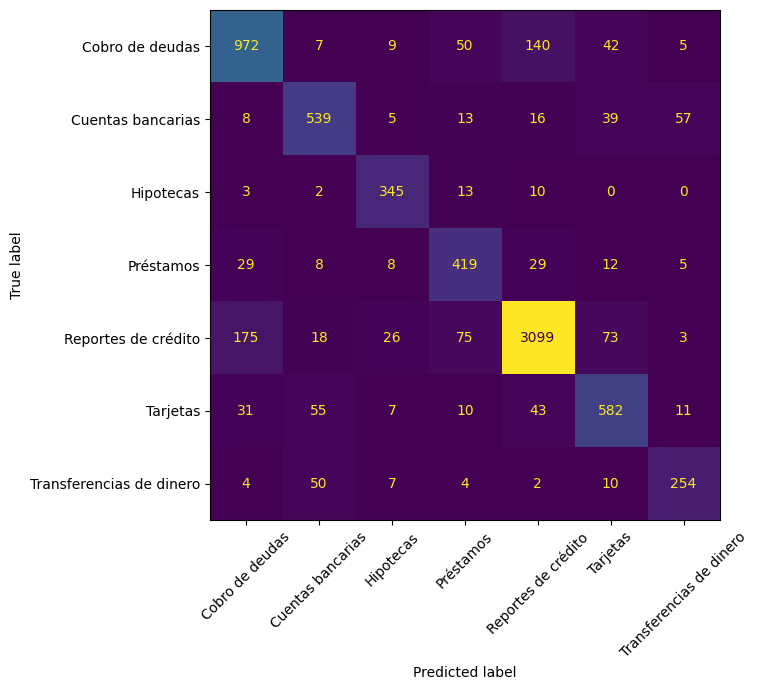

Latencia (GPU T4): p50 6.7 ms | p95 11.3 ms


In [ ]:
import time, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Evaluación en test
out = trainer.predict(ds_test)
pred = out.predictions.argmax(-1)
y = np.array(ds_test["label"])

print(classification_report(y, pred, target_names=etiquetas, digits=3))
mf1 = f1_score(y, pred, average="macro"); acc = accuracy_score(y, pred)
print(f"DistilBERT -> Macro-F1: {mf1:.4f} | Accuracy: {acc:.4f}")

base = json.load(open("/content/drive/MyDrive/metricas_baseline.json"))
print(f"Baseline   -> Macro-F1: {base['macro_f1']:.4f} | Accuracy: {base['accuracy']:.4f}")

# Matriz de confusión
cm = confusion_matrix(y, pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/cm_distilbert.png", dpi=150)
plt.show()

# Latencia por inferencia individual (p50 / p95)
model.eval(); dev = next(model.parameters()).device
tiempos = []
for t in test["texto"].sample(200, random_state=SEED):
    enc = tok(t, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(dev)
    t0 = time.perf_counter()
    with torch.no_grad():
        model(**enc)
    if dev.type == "cuda": torch.cuda.synchronize()
    tiempos.append((time.perf_counter() - t0) * 1000)
p50, p95 = np.percentile(tiempos, 50), np.percentile(tiempos, 95)
print(f"Latencia (GPU T4): p50 {p50:.1f} ms | p95 {p95:.1f} ms")

with open("/content/drive/MyDrive/metricas_distilbert.json", "w") as f:
    json.dump({"macro_f1": mf1, "accuracy": acc, "lat_p50_ms": p50, "lat_p95_ms": p95}, f)

In [ ]:
import re
from datetime import datetime, timedelta

# Regla de negocio: tema -> dependencia destino
DEPENDENCIA = {
    "Reportes de crédito": "Área de Reportes y Centrales de Riesgo",
    "Cobro de deudas": "Área de Cobranza y Recuperación",
    "Cuentas bancarias": "Área de Productos de Depósito",
    "Tarjetas": "Área de Tarjetas y Medios de Pago",
    "Hipotecas": "Área de Crédito Hipotecario",
    "Préstamos": "Área de Crédito de Consumo",
    "Transferencias de dinero": "Área de Giros y Transferencias",
}

# Etiquetas débiles de urgencia por palabras clave (NO es verdad real, se declara en el artículo)
ALTA = [r"fraud", r"scam", r"stolen", r"identity theft", r"foreclos", r"evict", r"lawsuit",
        r"sued", r"garnish", r"threat", r"harass", r"unauthorized", r"hacked",
        r"cannot (pay|afford)", r"homeless", r"emergency", r"urgent"]
MEDIA = [r"incorrect", r"wrong", r"error", r"dispute", r"not received", r"charged twice",
         r"late fee", r"overdraft", r"denied", r"closed my account", r"no response"]

def urgencia(texto):
    t = texto.lower()
    if any(re.search(p, t) for p in ALTA):
        return "Alta"
    if any(re.search(p, t) for p in MEDIA):
        return "Media"
    return "Baja"

# SLA por urgencia (valores asumidos para el prototipo)
SLA_DIAS = {"Alta": 1, "Media": 5, "Baja": 15}

def fecha_limite(u, desde=None):
    return (desde or datetime.now()) + timedelta(days=SLA_DIAS[u])

# Distribución de urgencia en train, para el artículo
train["urgencia_debil"] = train["texto"].apply(urgencia)
print(train["urgencia_debil"].value_counts(normalize=True).round(3))

urgencia_debil
Alta     0.395
Baja     0.331
Media    0.273
Name: proportion, dtype: float64


In [ ]:
import re, torch, gradio as gr
from datetime import datetime
from transformers import AutoTokenizer, AutoModelForSequenceClassification

RUTA_MODELO = "/content/drive/MyDrive/models/v1.0/distilbert_tema"
tok = AutoTokenizer.from_pretrained(RUTA_MODELO)
mdl = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO)
dev = "cuda" if torch.cuda.is_available() else "cpu"
mdl.to(dev).eval()
UMBRAL = 0.6

def limpiar_demo(t):
    t = re.sub(r"\S+@\S+", " ", t)
    t = re.sub(r"\b\+?\d[\d\-\s().]{7,}\d\b", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def clasificar(texto):
    if not texto or len(texto.split()) < 5:
        return "⚠️ Escribe al menos 5 palabras.", {}
    t = limpiar_demo(texto)
    enc = tok(t, truncation=True, max_length=256, return_tensors="pt").to(dev)
    with torch.no_grad():
        probs = torch.softmax(mdl(**enc).logits, dim=-1)[0].cpu()
    top = int(probs.argmax())
    tema = mdl.config.id2label[top]
    conf = float(probs[top])

    urg = urgencia(t)                      # definida en la celda 10
    dep = DEPENDENCIA[tema]                # definida en la celda 10
    limite = fecha_limite(urg).strftime("%Y-%m-%d %H:%M")

    aviso = ("\n\n⚠️ **Confianza baja: requiere revisión humana.**"
             if conf < UMBRAL else "")
    resumen = (f"**Tema:** {tema}  \n**Confianza:** {conf:.1%}  \n"
               f"**Urgencia (etiqueta débil por reglas):** {urg}  \n"
               f"**Dependencia destino:** {dep}  \n"
               f"**Fecha límite SLA:** {limite}{aviso}")
    vals, idxs = torch.topk(probs, 3)
    top3 = {mdl.config.id2label[int(i)]: float(v) for v, i in zip(vals, idxs)}
    return resumen, top3

demo = gr.Interface(
    fn=clasificar,
    inputs=gr.Textbox(lines=8, label="Solicitud o queja (el modelo fue entrenado con texto en inglés)"),
    outputs=[gr.Markdown(label="Resultado"), gr.Label(num_top_classes=3, label="Probabilidades (top 3)")],
    title="Clasificación y priorización de solicitudes",
    description="Prototipo: tema (DistilBERT), urgencia (reglas), dependencia (tabla) y SLA.",
    examples=[
        ["Someone opened a credit card in my name and I found unauthorized charges. I think my identity was stolen and I need this fixed urgently."],
        ["A collection agency keeps calling me about a debt that I already paid. They threatened to sue me and have not sent any written notice."],
    ],
    flagging_mode="never",
)
demo.launch(share=True, debug=True)

OSError: Repo id must be in the form 'repo_name' or 'namespace/repo_name': '/content/drive/MyDrive/models/v1.0/distilbert_tema'. Use `repo_type` argument if needed.